In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Exercise 1
a) Load house sales data from file kc_house_data.csv, print first records.
b) Print the variable list. Select categorical and numerical variables.
c) Compute basic statistics of numerical variables. Are all of them meaningful?

In [3]:
#a)
# Your code:
df = pd.read_csv("kc_house_data.csv")
df.head(1)

print("Rows and columns:", df.shape)

#Hint: read_csv(), head()

Rows and columns: (21613, 21)


In [4]:
#b)

house_categorical_df = ['id', 'date', 'waterfront', 'view', 'condition', 'grade', 'zipcode']
house_numerical_df = ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

print("Categorical", df[house_categorical_df])
print("Numerical", df[house_numerical_df])



Categorical                id             date  waterfront  view  condition  grade  \
0      7129300520  20141013T000000           0     0          3      7   
1      6414100192  20141209T000000           0     0          3      7   
2      5631500400  20150225T000000           0     0          3      6   
3      2487200875  20141209T000000           0     0          5      7   
4      1954400510  20150218T000000           0     0          3      8   
...           ...              ...         ...   ...        ...    ...   
21608   263000018  20140521T000000           0     0          3      8   
21609  6600060120  20150223T000000           0     0          3      8   
21610  1523300141  20140623T000000           0     0          3      7   
21611   291310100  20150116T000000           0     0          3      8   
21612  1523300157  20141015T000000           0     0          3      7   

       zipcode  
0        98178  
1        98125  
2        98028  
3        98136  
4        98074

In [5]:
#c)
#Your code:

print(df[house_numerical_df].describe())
# yr_built not all statistic
# yr_renovated as above
# lat and long are useless

#Hint: Function describe()

              price      bedrooms     bathrooms   sqft_living      sqft_lot  \
count  2.161300e+04  21613.000000  21613.000000  21613.000000  2.161300e+04   
mean   5.400881e+05      3.370842      2.114757   2079.899736  1.510697e+04   
std    3.671272e+05      0.930062      0.770163    918.440897  4.142051e+04   
min    7.500000e+04      0.000000      0.000000    290.000000  5.200000e+02   
25%    3.219500e+05      3.000000      1.750000   1427.000000  5.040000e+03   
50%    4.500000e+05      3.000000      2.250000   1910.000000  7.618000e+03   
75%    6.450000e+05      4.000000      2.500000   2550.000000  1.068800e+04   
max    7.700000e+06     33.000000      8.000000  13540.000000  1.651359e+06   

             floors    sqft_above  sqft_basement      yr_built  yr_renovated  \
count  21613.000000  21613.000000   21613.000000  21613.000000  21613.000000   
mean       1.494309   1788.390691     291.509045   1971.005136     84.402258   
std        0.539989    828.090978     442.575043

## Exercise 2
Using scatter plot:  
a) Show the relation of square footage and price.  
b) Check how price is influenced by apartment's grade. Find other variables correlated with price.  
c) Check how good apartments are distributed over the city. First, plot zipcode versus price. Then, use apartments coordinates (longitude and lattitude) in order to show where apartments of good grade are located.

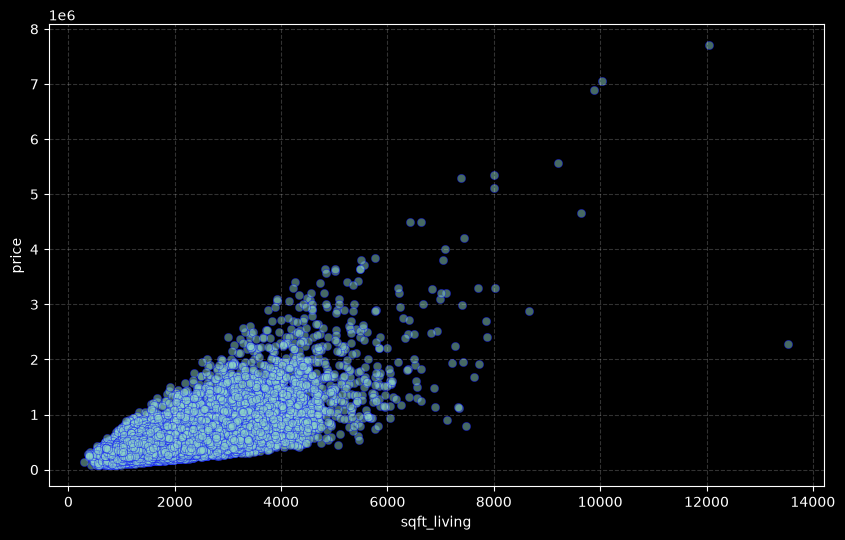

In [6]:
#a)
#Your code:
plt.figure(figsize=(10,6))
plt.scatter(df['sqft_living'], df['price'], alpha=0.5, edgecolors='blue', linewidths=0.5)
plt.xlabel("sqft_living")
plt.ylabel("price")
plt.grid(True, linestyle='--', alpha=0.2)
plt.show()

#Hint plt.scatter

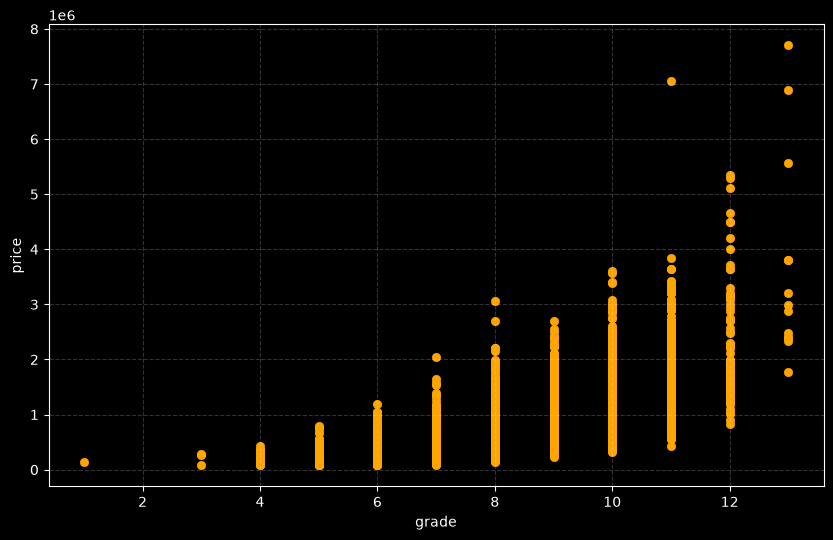

In [7]:
#b)
#Your code:
plt.figure(figsize=(10,6))
plt.scatter(df['grade'], df['price'], color='orange' , linewidths=.5)
plt.xlabel("grade")
plt.ylabel("price")
plt.grid(True, linestyle='--', alpha=0.2)
plt.show()


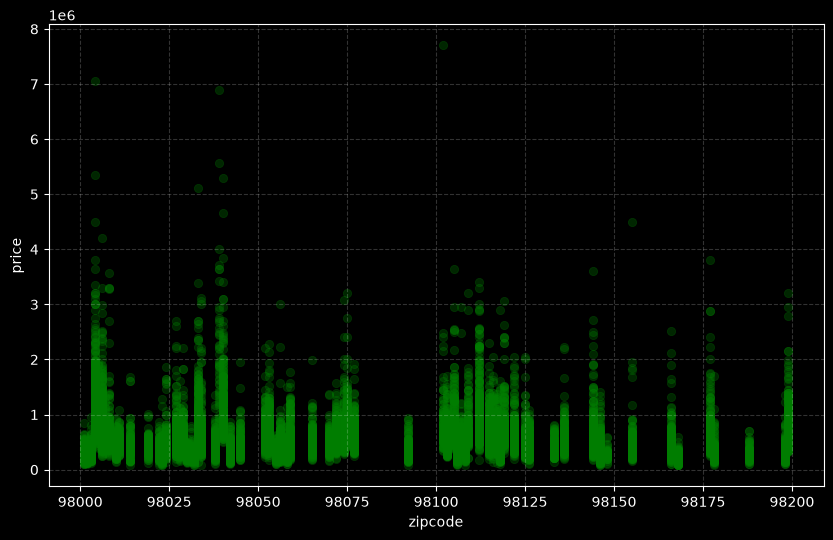

In [8]:
#c)
#Your code:
plt.figure(figsize=(10,6))
plt.scatter(df['zipcode'], df['price'], alpha=0.3, color='green', linewidths=.5)
plt.xlabel("zipcode")
plt.ylabel("price")
plt.grid(True, linestyle='--', alpha=0.2)
plt.show()


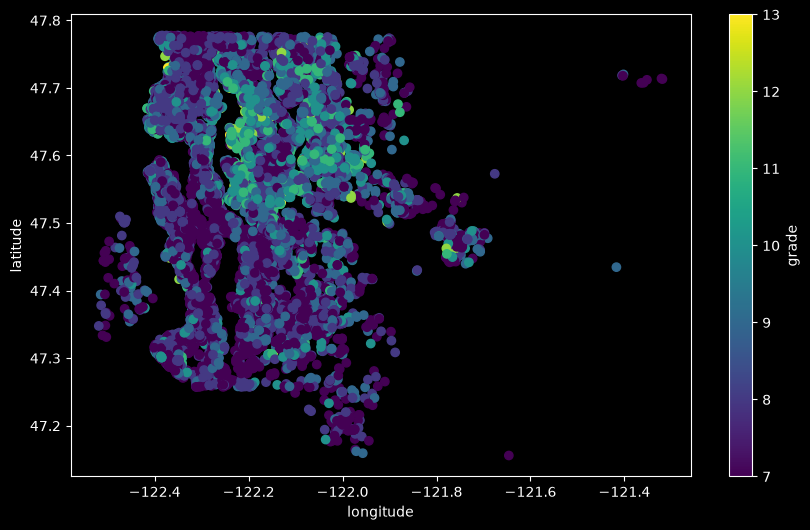

In [12]:
#Your code:
plt.figure(figsize=(10,6))
good_df = df[df['grade'] >= 7]
scatter = plt.scatter('long', 'lat', c='grade', cmap='viridis', data=good_df)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.colorbar(scatter, label='grade')
plt.show()


## Exercise 3
a) Create boxplot of apartment's grade versus it's price. Compare with plot 2b).  
b) Create mosaic plot of any two categorical variables.

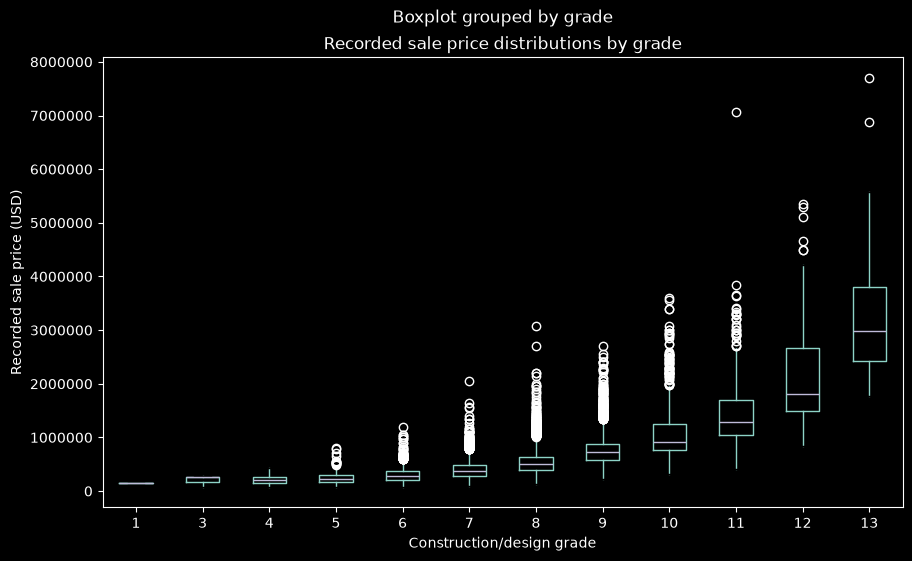

In [36]:
#a)
#Your code:
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(column="price", by="grade", ax=ax, grid=False)
ax.set_title("Recorded sale price distributions by grade")
ax.set_xlabel("Construction/design grade")
ax.set_ylabel("Recorded sale price (USD)")
ax.ticklabel_format(style="plain", axis="y")
plt.show()
#Hint: plt.boxplot

In [ ]:
#b)
from statsmodels.graphics.mosaicplot import mosaic

#Your code:



## Exercise 4
"I am interested in the house with 3 bedrooms, 2 bathrooms and 2 floors"  
a) Compute the basic statistics of apartments fulfilling above constraints.  
b) Distinct accepted apartments on any of previously created plots.
c) Find such apartments with best price to footage ratio.  

In [34]:
#a)
#Your code:
filtered_data = df.loc[(df['bedrooms'] == 3) & (df['bathrooms'] == 2) & (df['floors'] == 2)].copy()
print(filtered_data.describe())

#Hint: pandas.DataFrame.loc

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,1.540000e+02,1.540000e+02,154.0,154.0,154.000000,154.000000,154.0,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000
mean,4.397177e+09,5.144986e+05,3.0,2.0,1850.279221,23678.948052,2.0,0.006494,0.357143,3.435065,7.551948,1717.422078,132.857143,1969.779221,284.863636,98085.577922,47.567376,-122.247091,1802.337662,17545.123377
std,2.849813e+09,2.497661e+05,0.0,0.0,547.585413,83324.024708,0.0,0.080582,0.919495,0.713322,0.832684,527.473851,248.092631,34.654456,700.057328,48.808788,0.143221,0.150507,453.210930,40404.134611
min,7.600057e+06,2.090000e+05,3.0,2.0,1020.000000,700.000000,2.0,0.000000,0.000000,2.000000,6.000000,720.000000,0.000000,1900.000000,0.000000,98001.000000,47.194700,-122.519000,850.000000,886.000000
25%,2.060901e+09,3.769750e+05,3.0,2.0,1452.500000,3414.750000,2.0,0.000000,0.000000,3.000000,7.000000,1402.500000,0.000000,1942.250000,0.000000,98038.500000,47.498800,-122.361750,1452.500000,4020.000000
50%,3.630010e+09,4.640000e+05,3.0,2.0,1700.000000,5868.500000,2.0,0.000000,0.000000,3.000000,7.000000,1625.000000,0.000000,1984.500000,0.000000,98103.000000,47.584750,-122.299500,1725.000000,6278.000000
75%,7.184074e+09,5.894625e+05,3.0,2.0,2127.500000,10800.250000,2.0,0.000000,0.000000,4.000000,8.000000,1977.500000,207.500000,1997.500000,0.000000,98122.000000,47.682400,-122.149250,2117.500000,10392.250000
max,9.829200e+09,1.755000e+06,3.0,2.0,3650.000000,843309.000000,2.0,1.000000,4.000000,5.000000,10.000000,3650.000000,1120.000000,2014.000000,2014.000000,98199.000000,47.777000,-121.709000,3170.000000,273992.000000


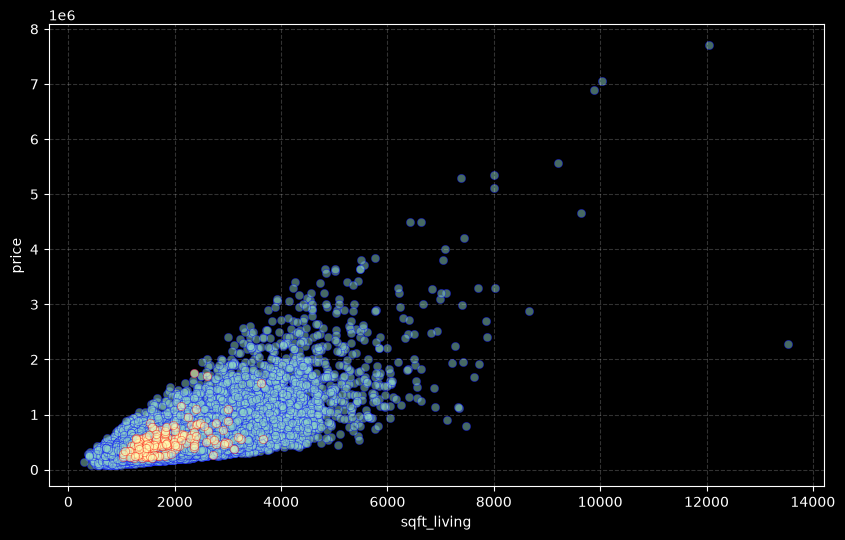

In [42]:
#b)
#Your code:
#It returns fig and ax in tuple
_, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df['sqft_living'], df['price'], alpha=0.5, edgecolors='blue', linewidths=0.5)
ax.scatter(filtered_data['sqft_living'], filtered_data['price'], alpha=0.5, edgecolors='red', linewidths=0.5)
plt.xlabel("sqft_living")
plt.ylabel("price")
plt.grid(True, linestyle='--', alpha=0.2)
plt.show()


In [41]:
#c)
#Your code:
filtered_data['price_per_sqft'] = filtered_data['price'] / filtered_data['sqft_living']
shortlist = filtered_data.sort_values(by='price_per_sqft', ascending=False)
shortlist.head(5)

#Hint: .loc, .sort_values(), .index

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price_per_sqft
9608,1337800805,20140703T000000,1755000.0,3,2.0,2360,4800,2.0,0,0,...,2360,0,1909,2014,98112,47.6317,-122.312,2260,4800,743.644068
5827,9829200250,20150105T000000,1697000.0,3,2.0,2600,6600,2.0,0,4,...,1930,670,1970,2014,98122,47.6055,-122.285,2670,6270,652.692308
10527,5318100935,20141020T000000,850000.0,3,2.0,1540,3600,2.0,0,0,...,1540,0,1900,1988,98112,47.6343,-122.283,2970,3600,551.948052
13853,6795100330,20140625T000000,1150000.0,3,2.0,2110,18815,2.0,0,0,...,2110,0,1979,0,98075,47.5836,-122.042,2690,21010,545.023697
14379,9829200325,20140617T000000,765000.0,3,2.0,1570,7000,2.0,0,2,...,1050,520,1971,0,98122,47.6061,-122.286,1990,6675,487.261146


In [45]:
#c)
#Your code:
df['price_per_sqft'] = df['price'] / df['sqft_living']
shortlist = df.sort_values(by='price_per_sqft', ascending=False)
shortlist.head(5)

#Hint: .loc, .sort_values(), .index

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price_per_sqft
19336,6021500970,20150407T000000,874950.0,2,1.00,1080,4000,1.0,0,0,...,1080,0,1940,0,98117,47.6902,-122.387,1530,4240,810.138889
4013,724069059,20140509T000000,2400000.0,3,2.25,3000,11665,1.5,1,4,...,3000,0,2001,0,98075,47.5884,-122.086,3000,15959,800.000000
10446,1118000320,20150508T000000,3400000.0,4,4.00,4260,11765,2.0,0,0,...,3280,980,1939,2010,98112,47.6380,-122.288,4260,10408,798.122066
8623,6303400395,20150130T000000,325000.0,1,0.75,410,8636,1.0,0,0,...,410,0,1953,0,98146,47.5077,-122.357,1190,8636,792.682927
9314,4389200610,20141201T000000,903000.0,2,1.50,1140,7800,1.0,0,0,...,1140,0,1947,0,98004,47.6142,-122.209,2020,7800,792.105263
